1159
800


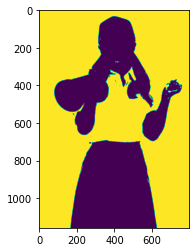

In [16]:
#先从图片中提取轮廓
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
# import xlwt

img = cv2.imread('D:/en/pic/nissinIMGL0778_TP_V4.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
low_hsv = np.array([0, 0, 221])
high_hsv = np.array([180, 30, 255])
mask = cv2.inRange(hsv, lowerb=low_hsv, upperb=high_hsv)

print(len(mask))
print(len(mask[0]))

list_y = []
list_x = []

for i in range(len(mask)):
#     print(mask[i])
    xmax = []
    for j in range(len(mask[i])):
        if mask[i][j] == 0:
#             print(mask[i][j],j,i)
            list_x.append(j)
            list_y.append(len(mask)-i)

# plt.plot(list_x, list_y, 'o', color='r')
# plt.show()

plt.imshow(mask)

# wb = xlwt.Workbook()

# ws = wb.add_sheet('sheet1')

# ws.write(0, 0, "x")
# ws.write(0, 1, "y")
# i = 1
# for x in list_x:
#     ws.write(i, 0, x)
#     i += 1

# j = 1
# for y in list_y:
#     ws.write(j, 1, y)
#     j += 1

# wb.save('D:/pyprj/ipython/datas/1111.xls')

df = pd.DataFrame({'x':list_x,'y':list_y})
df.to_excel('D:/pyprj/ipython/datas/tmp20230530.xlsx')


import plotly.io as pio
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import HTML


pio.renderers.default = 'iframe' # or 'notebook' or 'colab' or 'jupyterlab'
line1 = go.Scatter(x = list_x,y=list_y,name='line1',marker={"color": "rgba(102, 198, 147, 0.7)"})
fig = go.Figure(data=[line1])
fig.show()




In [27]:
np.argwhere(mask==0)

array([[  33,  393],
       [  33,  394],
       [  33,  395],
       ...,
       [1158,  622],
       [1158,  623],
       [1158,  624]], dtype=int64)

In [3]:
from pandas import DataFrame

data = { 'name': ['zs', 'ls', 'ww'], 'age': [11, 12, 13], 'gender': ['man', 'man', 'woman']}
df = DataFrame(data)
df.to_excel('D:/pyprj/ipython/datas/new.xlsx')

In [7]:
#有错误
import cv2,time
import numpy as np



def Three_element_add(array):
    array0 = array[:]
    array1 = np.append(array[1:],np.array([0]))
    array2 = np.append(array[2:],np.array([0, 0]))
    arr_sum = array0 + array1 + array2
    return arr_sum[:-2]


def VThin(image, array):
    NEXT = 1
    height, width = image.shape[:2]
    for i in range(1,height):
        M_all = Three_element_add(image[i])
        for j in range(1,width):
            if NEXT == 0:
                NEXT = 1
            else:
                M = M_all[j-1] if j<width-1 else 1
                if image[i, j] == 0 and M != 0:
                    a = np.zeros(9)
                    if height-1 > i and width-1 > j:
                        kernel = image[i - 1:i + 2, j - 1:j + 2]
                        a = np.where(kernel == 255, 1, 0)
                        a = a.reshape(1, -1)[0]
                    NUM = np.array([1,2,4,8,0,16,32,64,128])
                    sumArr = np.sum(a*NUM)
                    image[i, j] = array[sumArr] * 255
                    if array[sumArr] == 1:
                        NEXT = 0
    return image


def HThin(image, array):
    height, width = image.shape[:2]
    NEXT = 1
    for j in range(1,width):
        M_all = Three_element_add(image[:,j])
        for i in range(1,height):
            if NEXT == 0:
                NEXT = 1
            else:
                M = M_all[i-1] if i < height - 1 else 1
                if image[i, j] == 0 and M != 0:
                    a = np.zeros(9)
                    if height - 1 > i and width - 1 > j:
                        kernel = image[i - 1:i + 2, j - 1:j + 2]
                        a = np.where(kernel == 255, 1, 0)
                        a = a.reshape(1, -1)[0]
                    NUM = np.array([1, 2, 4, 8, 0, 16, 32, 64, 128])
                    sumArr = np.sum(a * NUM)
                    image[i, j] = array[sumArr] * 255
                    if array[sumArr] == 1:
                        NEXT = 0
    return image


def Xihua(binary, array, num=10):
    binary_image = binary.copy()
    image = cv2.copyMakeBorder(binary_image, 1, 0, 1, 0, cv2.BORDER_CONSTANT, value=0)
    for i in range(num):
        VThin(image, array)
        HThin(image, array)
    return image


array = [0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,\
         1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,\
         0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,\
         1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,\
         1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,\
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,\
         1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,\
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,\
         0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,\
         1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,\
         0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,\
         1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,\
         1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,\
         1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,\
         1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0,\
         1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0]


if __name__ == '__main__':
    image = cv2.imread('D:/en/pic/nissinIMGL0778_TP_V4.jpg', 0)
    ret, binary = cv2.threshold(image, 70, 255, cv2.THRESH_BINARY)
    cv2.imshow('image', image)
    cv2.imshow('binary', binary)
    cv2.waitKey(0)

    t1 = time.time()

    iThin = Xihua(binary, array)
    t2 = time.time()
    print('cost time:',t2-t1)
    cv2.imshow('iThin', iThin)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


TypeError: list indices must be integers or slices, not numpy.float64

In [14]:
len(array)

256

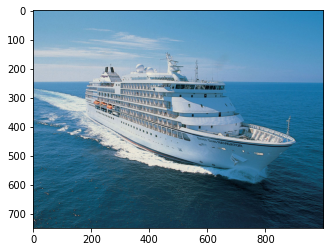

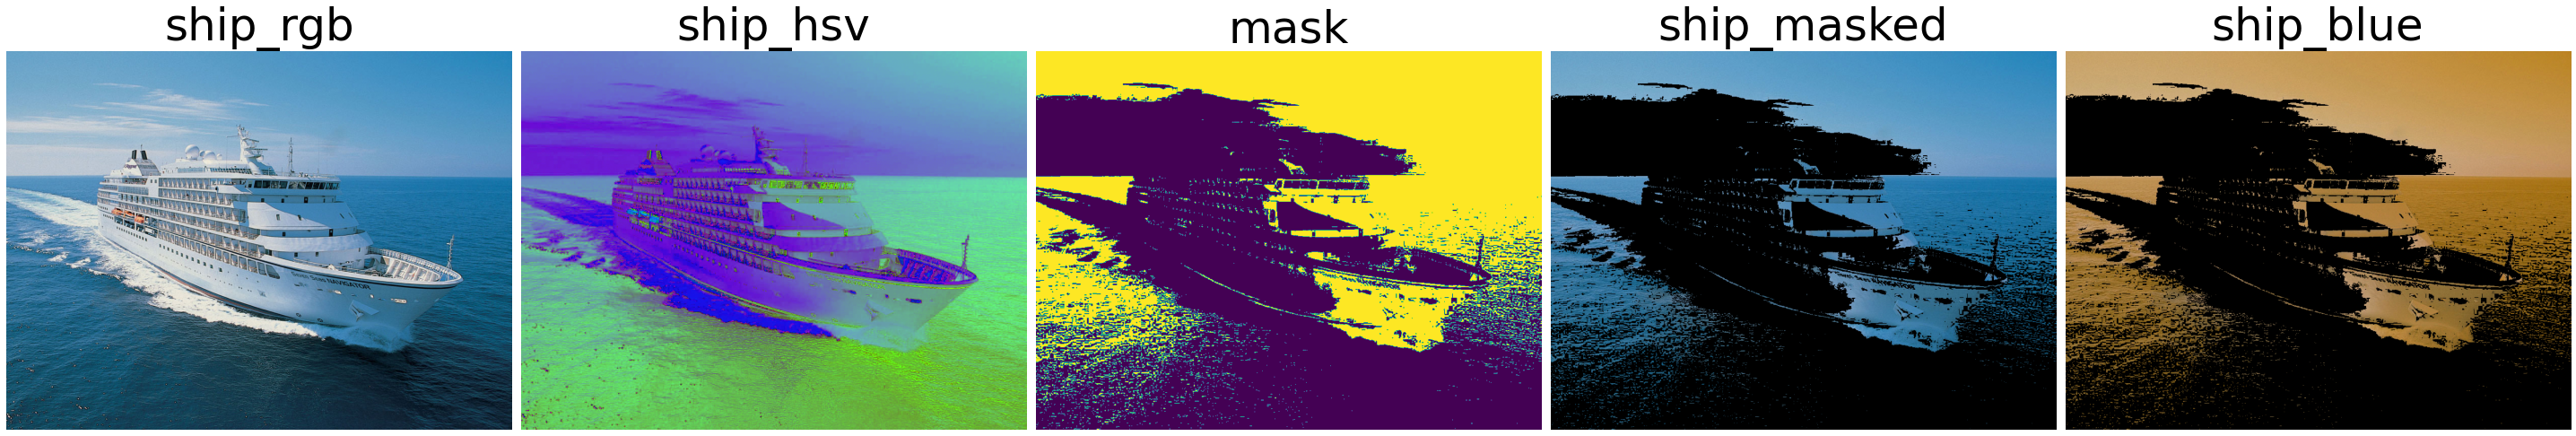

In [13]:
#颜色分离
# 导入模块，输出原图
import cv2
import matplotlib.pyplot as plt
ship_rgb = cv2.imread('D:/en/pic/R-C.jpg')[:,:,::-1]
plt.imshow(ship_rgb)
plt.show()

# 将图像转为HSV格式进而得到mask，HSV分别代表色相(Hue)、饱和度(Saturation)、明度(Value)
ship_hsv = cv2.cvtColor(ship_rgb, cv2.COLOR_RGB2HSV)
# 设定参数lowerb、upperb
import numpy as np
lowerb = np.array([100,100,100])
upperb = np.array([140,255,255])
# 获取mask
mask = cv2.inRange(ship_hsv, lowerb, upperb)
# 利用mask进行颜色分离
ship_masked = cv2.bitwise_and(ship_rgb,ship_rgb,mask=mask)
# 转回RGB格式
ship_blue = cv2.cvtColor(ship_masked,cv2.COLOR_BGR2RGB)

image_list = [ship_rgb,ship_hsv,mask,ship_masked,ship_blue]
title_list = ['ship_rgb','ship_hsv','mask','ship_masked','ship_blue']
plt.figure(figsize=(40,8))
for i in range(len(title_list)):
    plt.subplot(1,5,i+1)
    plt.imshow(image_list[i])
    plt.axis('off')
    plt.title(title_list[i],size=50)
plt.tight_layout()
plt.show()





In [18]:
#先将图像进行灰度化，然后进行二值化处理
'''
将图像上的像素点的灰度值设为0或255，整个图像呈现出黑白效果。
所有灰度大于或等于阈值的像素被判定为属于特定物体，其灰度值为255表示，
否则这些像素点被排除在物体区域以外，灰度值为0，表示背景或者例外的物体区域。
'''
# 图片二值化
from PIL import Image
img = Image.open('D:/en/pic/nissinIMGL0778_TP_V4.jpg')
 
# 模式L”为灰色图像
Img = img.convert('L')
Img.save("test1.jpg") #保存
 
# 自定义灰度界限
threshold = 200
table = []
for i in range(256):
    if i < threshold:
        table.append(0)
    else:
        table.append(1)
 
# 二值化并保存
photo = Img.point(table, '1')
photo.save("test2.jpg")


In [42]:
from PIL import Image
from PIL import ImageFilter  
im = Image.open('D:/en/pic/nissinIMGL0778_TP_V4.jpg')
print(im.format, im.size, im.mode)

r,g,b = im.split()
print(r.mode)
print(r.size)
print(im.size)
im.show()
r.show()
g.show()
b.show()










JPEG (800, 1159) RGB
L
(800, 1159)
(800, 1159)


In [ ]:
# 导入相应的pthon包
from PIL import Image
from scipy.spatial import distance as dist
from imutils import perspective
from imutils import contours
import numpy as np
import argparse
import imutils
import cv2

def draw_rect(cnts,orig):
    for c in cnts:
    # 过滤点太小的轮廓点
       if cv2.contourArea(c) < 100:
           continue
	# 计算最小的外接矩形
       box = cv2.minAreaRect(c)
       box = cv2.cv.BoxPoints(box) if imutils.is_cv2() else cv2.boxPoints(box)
       box = np.array(box, dtype="int")

	# 对轮廓点进行排序:左上、右上、右下、左下
       box = perspective.order_points(box)	
	
	# 绘制轮廓
	#cv2.drawContours(orig, [box.astype("int")], -1, (0, 255, 0), 1)
       cv2.drawContours(orig, [c.astype("int")],-1, (0, 255, 0), 2)
    return orig
	
# 进行参数配置和解析
ap = argparse.ArgumentParser()
ap.add_argument("-i", "--image", required=True, help="path to the input image")
args = vars(ap.parse_args())

# 读取图片
image = cv2.imread(args["image"])
#image = cv2.imread('/home/e/01.jpg')
# 执行灰度变换
#颜色空间转换函数，需要转换的图片，转换成何种格式。
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
# 执行高斯滤波
gray = cv2.GaussianBlur(gray, (7, 7), 0)

# 执行Canny边缘检测
edged = cv2.Canny(gray, 50, 100)
# 执行腐蚀和膨胀处理
edged = cv2.dilate(edged, None, iterations=1)
edged = cv2.erode(edged, None, iterations=1)
# 在边缘映射中寻找轮廓
cnts = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)

# 对轮廓点进行排序
(cnts, _) = contours.sort_contours(cnts)
# 设置显示颜色
colors = ((0, 0, 255), (240, 0, 159), (0, 165, 255), (255, 255, 0), (255, 0, 255))

orig=image.copy()
#画框
orig=draw_rect(cnts,orig)

# 显示结果
cv2.imshow("Image", orig)
cv2.imwrite('cnts.jpg',orig)

#cv2.imshow("mask", mask)
#cv2.imwrite('d.jpg',mask)

cv2.waitKey(0)



